## **BMI500 Lecture 7 Homework**
### ***Question 2: Agent-Based Modeling of Pandemic Spread***

### **Part A. Building the Base Model: Infection Dynamics in a Population** 

#### Import necessary libraries

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random

#### Environment and initial conditions

In [6]:
# Simulation parameters
grid_size = 20
n_agents = 200
n_steps = 300
n_runs = 20

# Infection and recovery probabilities
p_values = [0.15, 0.3]
q_values = [0.02, 0.04]

# Agent states: 0 = Susceptible, 1 = Infected, 2 = Recovered
state_names = ['Susceptible', 'Infected', 'Recovered']
colors = ['blue', 'red', 'green']

#### Agentic behaviors

In [7]:
def simulate(p, q, seed=None):
    rng = np.random.default_rng(seed)

    # Random initial positions (x, y) for 200 agents
    positions = rng.integers(0, grid_size, size=(n_agents, 2))

    # Initial states: 195 S, 5 I, 0 R
    states = np.array([0]*195 + [1]*5)

    # Record S, I, R counts over time (including time 0)
    counts = np.zeros((n_steps + 1, 3))
    counts[0] = np.bincount(states, minlength=3)

    # Possible moves: stay, up, down, left, right
    moves = np.array([
        [0, 0],
        [-1, 0],
        [1, 0],
        [0, -1],
        [0, 1]
    ])

    for t in range(1, n_steps + 1):

        # Step 1: Random movement
        random_moves = moves[rng.integers(0, 5, size=n_agents)]
        positions = np.clip(positions + random_moves, 0, grid_size - 1)

        # Step 2: Identify cells containing infected agents
        infected_grid = np.zeros((grid_size, grid_size), dtype=bool)

        infected_positions = positions[states == 1]
        infected_grid[infected_positions[:, 0], infected_positions[:, 1]] = True

        # Step 3: Susceptible agents become infected with probability p
        exposed = infected_grid[positions[:, 0], positions[:, 1]]
        new_infections = (states == 0) & exposed & (rng.random(n_agents) < p)

        # Step 4: Infected agents recover with probability q
        recoveries = (states == 1) & (rng.random(n_agents) < q)

        # Update states simultaneously
        states[new_infections] = 1
        states[recoveries] = 2

        # Step 5: Record counts
        counts[t] = np.bincount(states, minlength=3)

    return counts

#### Simulation (300 time steps)

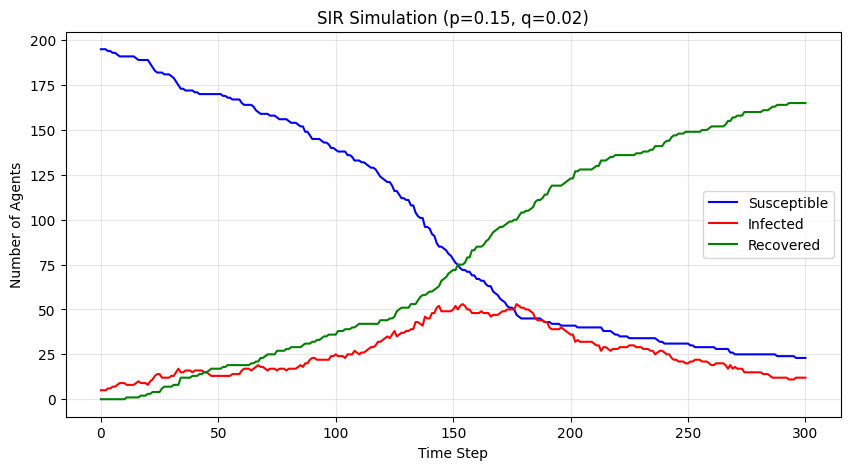

In [57]:
counts = simulate(p=0.15, q=0.02, seed=42)

plt.figure(figsize=(10, 5))

for i in range(3):
    plt.plot(counts[:, i], color=colors[i], label=state_names[i])

plt.xlabel('Time Step')
plt.ylabel('Number of Agents')
plt.title('SIR Simulation (p=0.15, q=0.02)')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("sir_simulations.png", dpi=300, bbox_inches="tight")
plt.show()

#### Sensitivity analysis

In [53]:
results = {}

for p in p_values:
    for q in q_values:

        runs = []

        for run in range(n_runs): # repeat for 20 simulations
            counts = simulate(p, q, seed=run)
            runs.append(counts)

        results[(p, q)] = np.array(runs)

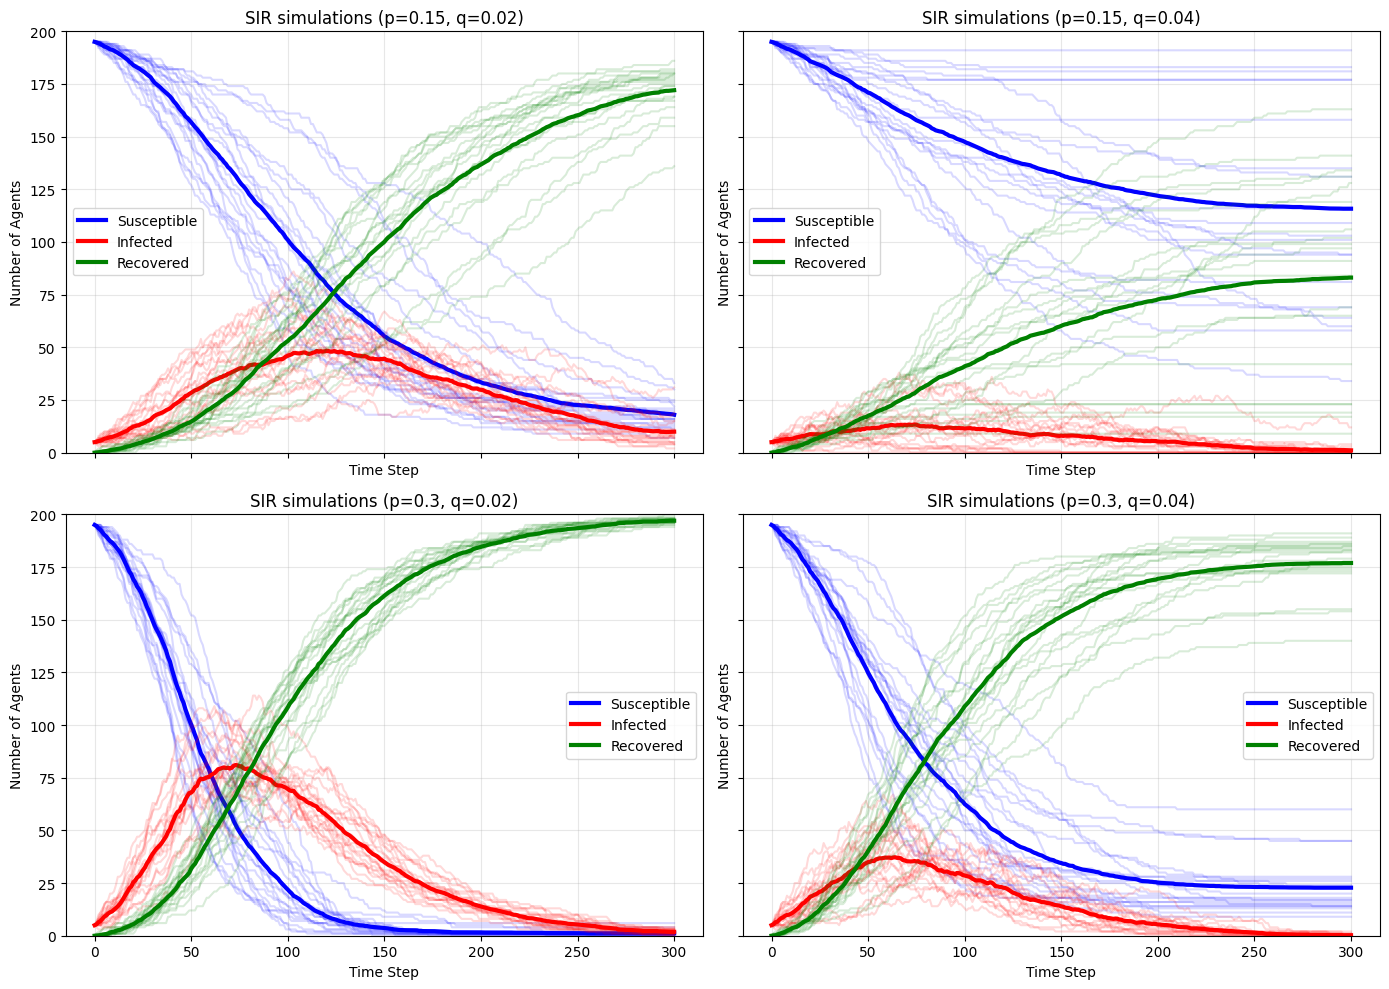

In [54]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)

for ax, ((p, q), runs) in zip(axes.flat, results.items()):

    avg = runs.mean(axis=0)

    for i in range(3):

        # Plot 20 individual runs
        for run in runs:
            ax.plot(run[:, i], color=colors[i], alpha=0.15)

        # Plot average
        ax.plot(avg[:, i], color=colors[i],
                linewidth=3, label=state_names[i])

    ax.set_title(f'SIR simulations (p={p}, q={q})')
    ax.set_xlabel('Time Step')
    ax.set_ylabel('Number of Agents')
    ax.set_ylim(0, 200)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
fig.savefig("sir_simulations_combination.png", dpi=300, bbox_inches="tight")
plt.show()

In [25]:
summary = []

for (p, q), runs in results.items():

    infected = runs[:, :, 1]  # Infected counts for all 20 runs

    # Peak infected agents and time to peak for each run
    peaks = infected.max(axis=1)
    peak_times = infected.argmax(axis=1)

    # Total ever infected by step 300 (Infected + Recovered)
    total_infected = runs[:, -1, 1] + runs[:, -1, 2]

    # Number of runs where infections die out by step 100
    early_dieout = np.sum(infected[:, 100] == 0)

    # Standard deviation across runs, averaged over all time steps and SIR states
    variability = runs.std(axis=0).mean()

    summary.append({
        'p': p,
        'q': q,
        'Avg Peak Infected': peaks.mean(),
        'Avg Time to Peak': peak_times.mean(),
        'Avg Total Ever Infected': total_infected.mean(),
        'Early Dieout Runs': early_dieout,
        'Mean SIR Std Dev': variability
    })

df_summary = pd.DataFrame(summary)

# Save to CSV
df_summary.to_csv('sir_summary.csv', index=False)

display(df_summary)

,p,q,Avg Peak Infected,Avg Time to Peak,Avg Total Ever Infected,Early Dieout Runs,Mean SIR Std Dev
0,0.15,0.02,58.55,127.05,182.00,0,15.084610
1,0.15,0.04,19.35,70.55,84.20,3,22.276698
2,0.30,0.02,89.10,71.60,198.85,0,7.083295
3,0.30,0.04,45.05,74.65,177.20,0,12.917064


**Interpretation**: 

- Increasing p increased the average total number of agents ever infected. At q = 0.02, doubling p increased the average peak infected from 59 to 89 agents and total infection from 182 to 199 agents. The average time to reach the peak also reduced from 127 time steps to 72 steps. This trend holds true for doubling p at q = 0.04, where the peak and total infections also increased. The average time to peak, however, increased as p increased for q = 0.04. 

- Meanwhile, increasing q reduced the outbreak severity. At p = 0.15, doubling q reduced the average peak infected from 59 to 19 and total infected from 182  to 84. At p = 0.3, doubling q reduced the peak from 89 to 45 and total infections from 199 to 177. The effect on peak timing is not obvious, given that doubling q reduced time to peak for p = 0.15 but slightly deplayed the time to peak for p = 0.3.

- Based on the mean SIR standard deviations (variation across the entire SIR curves), we can see the individuals runs are fairly consistent and resembles the average. The variation between runs was greatest at p = 0.15 and q = 0.04 (SD = 22.28). The SIR curves were most consistent when infection probability (p) was high and recovery probability (q) was low. 

- Assuming 'early' means after 100 time steps zero infected agents were reached, it only occurred when p = 0.15 and q = 0.04 at 3 of 20 runs (~15%).  

### **Part B. Extending the Model: Social Distancing and Interventions**

#### Introduce social distancing measures with p= 0.3 and q= 0.02

In [58]:
grid_size = 20
n_agents = 200
n_steps = 300
n_runs = 20

p = 0.3
q = 0.02
m = 0.5  # Probability of movement for reduced movement measure

state_names = ['Susceptible', 'Infected', 'Recovered']
colors = ['blue', 'red', 'green']

In [8]:
def simulate_distancing(p, q, measure, m=0.5, seed=None):
    rng = np.random.default_rng(seed)

    # Initialize positions and states
    positions = rng.integers(0, grid_size, size=(n_agents, 2))
    states = np.array([0]*195 + [1]*5)

    counts = np.zeros((n_steps + 1, 3))
    counts[0] = np.bincount(states, minlength=3)

    directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    for t in range(1, n_steps + 1):

        # Identify cells currently occupied by infected agents
        infected_cells = set(map(tuple, positions[states == 1]))

        # Step 1: Movement
        for i in range(n_agents):
            x, y = positions[i]

            # Find valid neighboring cells
            neighbors = [
                (x + dx, y + dy)
                for dx, dy in directions
                if 0 <= x + dx < grid_size and 0 <= y + dy < grid_size
            ]

            if measure == 'reduced':
                # Move with probability m
                if rng.random() < m:
                    positions[i] = neighbors[rng.integers(len(neighbors))]

            elif measure == 'avoidance':
                if states[i] == 0:
                    # Susceptible agents avoid infected cells
                    safe = [cell for cell in neighbors if cell not in infected_cells]

                    if safe:
                        positions[i] = safe[rng.integers(len(safe))]
                    # Otherwise, stay in place

                else:
                    # Infected/recovered agents move normally or stay
                    choices = neighbors + [(x, y)]
                    positions[i] = choices[rng.integers(len(choices))]

        # Step 2: Identify infected cells after movement
        infected_grid = np.zeros((grid_size, grid_size), dtype=bool)
        infected_pos = positions[states == 1]
        infected_grid[infected_pos[:, 0], infected_pos[:, 1]] = True

        # Step 3: Infection
        exposed = infected_grid[positions[:, 0], positions[:, 1]]
        new_infections = (states == 0) & exposed & (rng.random(n_agents) < p)

        # Step 4: Recovery
        recoveries = (states == 1) & (rng.random(n_agents) < q)

        states[new_infections] = 1
        states[recoveries] = 2

        # Step 5: Record counts
        counts[t] = np.bincount(states, minlength=3)

    return counts

In [60]:
measures = ['reduced', 'avoidance']
results_distancing = {}

for measure in measures:
    runs = []

    for run in range(n_runs):
        counts = simulate_distancing(p, q, measure, m=m, seed=run)
        runs.append(counts)

    results_distancing[measure] = np.array(runs)

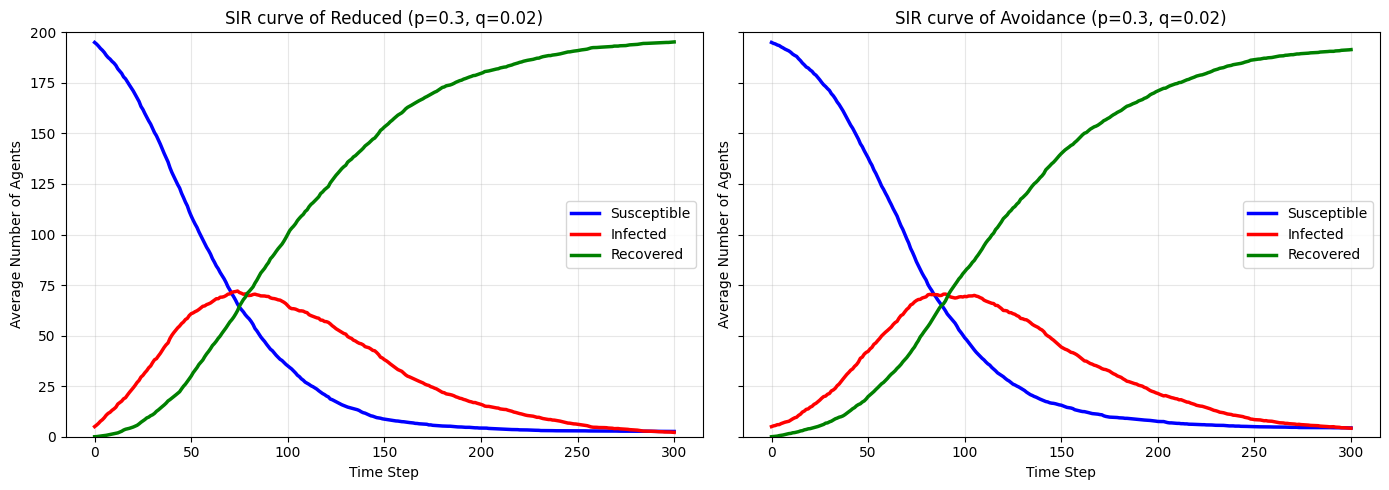

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

for ax, measure in zip(axes, measures):

    runs = results_distancing[measure]
    avg = runs.mean(axis=0)

    for i in range(3):
        ax.plot(avg[:, i], color=colors[i],
                linewidth=2.5, label=state_names[i])

    ax.set_title(f'SIR curve of {measure.capitalize()} (p={p}, q={q})')
    ax.set_xlabel('Time Step')
    ax.set_ylabel('Average Number of Agents')
    ax.set_ylim(0, 200)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
fig.savefig("sir_distancing_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

In [46]:
print(f"p = 0.3, q = 0.02: ")

for measure, runs in results_distancing.items():

    infected = runs[:, :, 1]

    avg_peak = infected.max(axis=1).mean()
    avg_peak_time = infected.argmax(axis=1).mean()
    avg_total_infected = (runs[:, -1, 1] + runs[:, -1, 2]).mean()
    print(f'\n{measure.capitalize()}:')
    print(f'Average peak infections: {avg_peak:.2f}')
    print(f'Average time to peak: {avg_peak_time:.2f}')
    print(f'Average total ever infected: {avg_total_infected:.2f}')

p = 0.3, q = 0.02: 

Reduced:
Average peak infections: 78.95
Average time to peak: 73.85
Average total ever infected: 197.40

Avoidance:
Average peak infections: 79.10
Average time to peak: 92.75
Average total ever infected: 195.65


Recall that without social distancing:
- Average peak infections: 89.10	
- Average time to peak: 71.60	
- Average total ever infected: 198.85

**Interpretations**:
- The maximum number of simultaneously affected agents is determined by infection probability (p), recovery probability (q), and movement probability (m). A high p, low q, and m close to 1 would cause the most severe outbreak. 

- The peak infection count determines whether the healthcare system is overwhelmed because it creates the greatest burden. To truly determine healthcare overload, additioanl information is needed (e.g., the capacity of the hospital).

#### Compare the results with and without social distancing

In [47]:
# Parameters
n_steps = 1000
p = 0.3
q = 0.02
m = 0.5

measures = ['original', 'reduced', 'avoidance']
records = []

for measure in measures:
    for run in range(20):

        # Run simulation
        if measure == 'original':
            counts = simulate(p, q, seed=run)
        else:
            counts = simulate_distancing(p, q, measure, m=m, seed=run)

        # Find first time step with zero infected agents
        zero_steps = np.where(counts[:, 1] == 0)[0]

        # Record NaN if infections remain after 1000 steps
        time_to_zero = zero_steps[0] if len(zero_steps) > 0 else np.nan

        records.append({
            'Measure': measure,
            'Run': run + 1,
            'Time to Zero': time_to_zero
        })

# Store individual run results
df_times = pd.DataFrame(records)

# Calculate average time across runs
df_summary = df_times.groupby('Measure').agg(
    Avg_Time_to_Zero=('Time to Zero', 'mean'),
    Runs_Reached_Zero=('Time to Zero', 'count')
).reset_index()

# Save results
df_times.to_csv('sir_time_to_zero_runs.csv', index=False)
df_summary.to_csv('sir_time_to_zero_summary.csv', index=False)

display(df_summary)

,Measure,Avg_Time_to_Zero,Runs_Reached_Zero
0,avoidance,409.15,20
1,original,364.75,20
2,reduced,397.55,20


- **Peak infections**: With the introduction of social distancing, the peak number of infected agents decreased from 89 to 78.95 (reduced) and 79.10 (avoidance). 

- **Peak timing and duration**: The time to the peak is delayed from 71.60 time steps to 73.85 (reduced) and 92.75 (avoidance). However, the average time until no infected agents remained increased from 364.75 time steps to 397.55 (reduced) and 409.15 (avoidance), suggesting social distancing can cause a longer outbreak despite having a lower peak. 

- **Total number of agents infected**: The total number of infections is slightly reduced from 99.4% to 98.7% (reduced) and 97.8% (avoidance). Distancing primarily changed the outbreak's timing and peak infections rather than the total impact size. 

- **Implications for real-world public health interventions**: During a pandemic, reducing contact through social distancing can reduce peak demand and delay infection peak, thereby alleviating the burden of healthcare systems. However, social distancing alone is insufficient to prevent the spread of the pandemic. 

#### Strength of distancing

,m,Avg Peak Infected,Avg Time to Peak
0,0.1,22.05,124.80
1,0.3,64.10,110.05
2,0.6,87.50,79.00
3,1.0,72.60,78.20


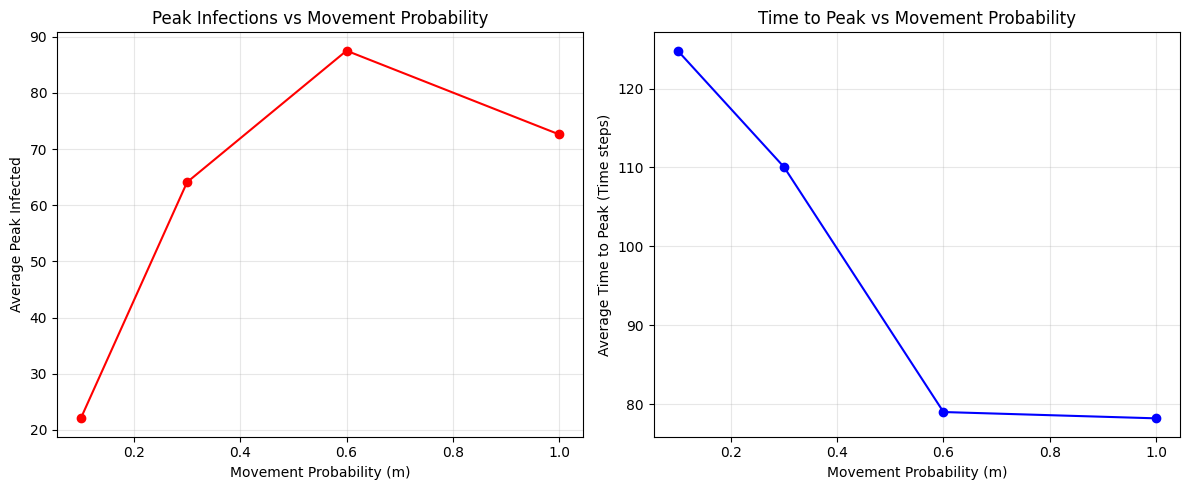

In [62]:
# Parameters
n_steps = 300
p = 0.3
q = 0.02
m_values = [0.1, 0.3, 0.6, 1.0]
n_runs = 20

results_m = []

for m in m_values:

    peaks = []
    peak_times = []

    for run in range(n_runs):
        counts = simulate_distancing(p, q, 'reduced', m=m, seed=run)

        infected = counts[:, 1]

        peaks.append(infected.max())
        peak_times.append(infected.argmax())

    results_m.append({
        'm': m,
        'Avg Peak Infected': np.mean(peaks),
        'Avg Time to Peak': np.mean(peak_times)
    })

df_m = pd.DataFrame(results_m)
display(df_m)

# Plot results
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Average peak infected vs m
axes[0].plot(df_m['m'], df_m['Avg Peak Infected'], 'o-', color='red')
axes[0].set_xlabel('Movement Probability (m)')
axes[0].set_ylabel('Average Peak Infected')
axes[0].set_title('Peak Infections vs Movement Probability')
axes[0].grid(alpha=0.3)

# Average time to peak vs m
axes[1].plot(df_m['m'], df_m['Avg Time to Peak'], 'o-', color='blue')
axes[1].set_xlabel('Movement Probability (m)')
axes[1].set_ylabel('Average Time to Peak (Time steps)')
axes[1].set_title('Time to Peak vs Movement Probability')
axes[1].grid(alpha=0.3)

plt.tight_layout()
fig.savefig("distancing_vs_movement_prob.png", dpi=300, bbox_inches="tight")
plt.show()

**Interpretation**: Stricter social distancing (lower m) delays the average time to peak because it reduces transmission opportunities. It also leads to smaller infection scale and lower average peak infections. Relaxing distancing is generally associated with a faster and larger outbreak, but the increase is not consistent for all m (decreased from 87.5 for m = 0.6 to 72.6 for m = 1.0).

### **Additional analysis: Effect of quarantine**

We would like to test whether restricting movement specifically among infected agents can control an outbreak while allowing the rest of the population to move normally (mimicking the effect of quarantine). The current reduced movement model restricts everyone’s movement and the avoidance model changes susceptible agents’ behavior. The quarantine model investigates whether targeting agents capable of transmitting infection is a more effective social distancing measure.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def simulate_quarantine(p, q, m, seed=None):
    rng = np.random.default_rng(seed)

    # Initialize positions and states
    positions = rng.integers(0, 20, size=(200, 2))
    states = np.array([0]*195 + [1]*5)

    counts = np.zeros((301, 3))
    counts[0] = np.bincount(states, minlength=3)

    directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    for t in range(1, 301):

        # Step 1: Movement
        for i in range(200):

            # Infected agents move with probability m
            # Other agents move with probability 1
            move_prob = m if states[i] == 1 else 1.0

            if rng.random() < move_prob:
                x, y = positions[i]

                # Find valid neighboring cells
                neighbors = [
                    (x + dx, y + dy)
                    for dx, dy in directions
                    if 0 <= x + dx < 20 and 0 <= y + dy < 20
                ]

                positions[i] = neighbors[rng.integers(len(neighbors))]

        # Step 2: Identify infected cells after movement
        infected_grid = np.zeros((20, 20), dtype=bool)
        infected_pos = positions[states == 1]
        infected_grid[infected_pos[:, 0], infected_pos[:, 1]] = True

        # Step 3: Infection
        exposed = infected_grid[positions[:, 0], positions[:, 1]]
        new_infections = (states == 0) & exposed & (rng.random(200) < p)

        # Step 4: Recovery
        recoveries = (states == 1) & (rng.random(200) < q)

        states[new_infections] = 1
        states[recoveries] = 2

        # Step 5: Record counts
        counts[t] = np.bincount(states, minlength=3)

    return counts

In [2]:
p = 0.3
q = 0.02
m_values = [0.1, 0.2, 0.5]
n_runs = 20

results_quarantine = {}

for m in m_values:
    runs = []

    for run in range(n_runs):
        counts = simulate_quarantine(p, q, m, seed=run)
        runs.append(counts)

    results_quarantine[m] = np.array(runs)

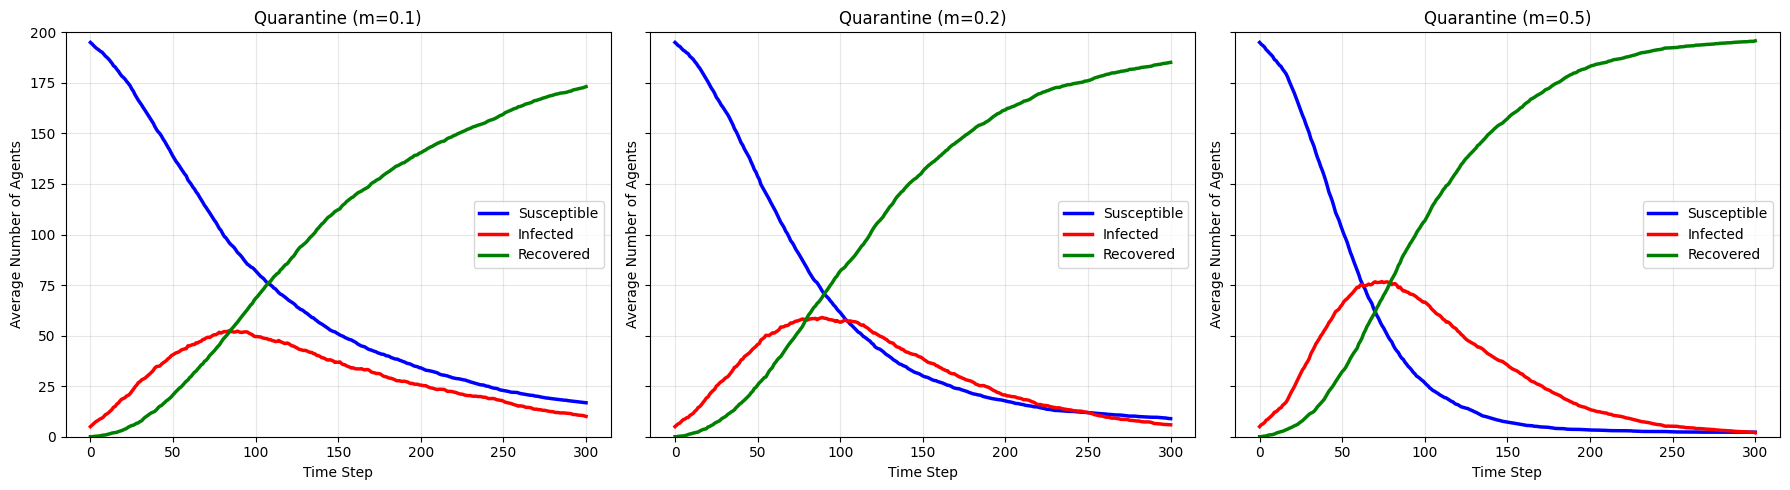

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

colors = ['blue', 'red', 'green']
state_names = ['Susceptible', 'Infected', 'Recovered']

for ax, m in zip(axes, m_values):

    runs = results_quarantine[m]
    avg = runs.mean(axis=0)

    for i in range(3):
        ax.plot(avg[:, i], color=colors[i],
                linewidth=2.5, label=state_names[i])

    ax.set_title(f'Quarantine (m={m})')
    ax.set_xlabel('Time Step')
    ax.set_ylabel('Average Number of Agents')
    ax.set_ylim(0, 200)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [4]:
summary = []

for m, runs in results_quarantine.items():

    infected = runs[:, :, 1]

    peaks = infected.max(axis=1)
    peak_times = infected.argmax(axis=1)
    total_infected = runs[:, -1, 1] + runs[:, -1, 2]

    summary.append({
        'm': m,
        'Avg Peak Infected': peaks.mean(),
        'Avg Time to Peak': peak_times.mean(),
        'Avg Total Ever Infected': total_infected.mean()
    })

df_quarantine = pd.DataFrame(summary)

display(df_quarantine)

,m,Avg Peak Infected,Avg Time to Peak,Avg Total Ever Infected
0,0.1,56.45,93.05,183.20
1,0.2,65.15,90.50,191.05
2,0.5,84.75,70.75,197.75


**Interpretation**: When m = 0.5, the quarantine measure yielded average peak infection to 84.75, which is higher compared to reduced movement (78.95) and avoidance (79.10). The average time to peak is the shortest among the three (70.75 steps). The average total ever infected did not change much. These results suggest that, under the tested conditions, restricting only infected agents’ movement was less effective at lowering and delaying the infection peak than the other two measures. One possible explanation is that susceptible agents continued moving and could still encounter infected agents, even when those infected agents stayed in place. Partial quarantine alone provided limited control of the outbreak in this model.

### **Plotting for Presentation: SIR curve for original, reduced movement, and avoidance models**

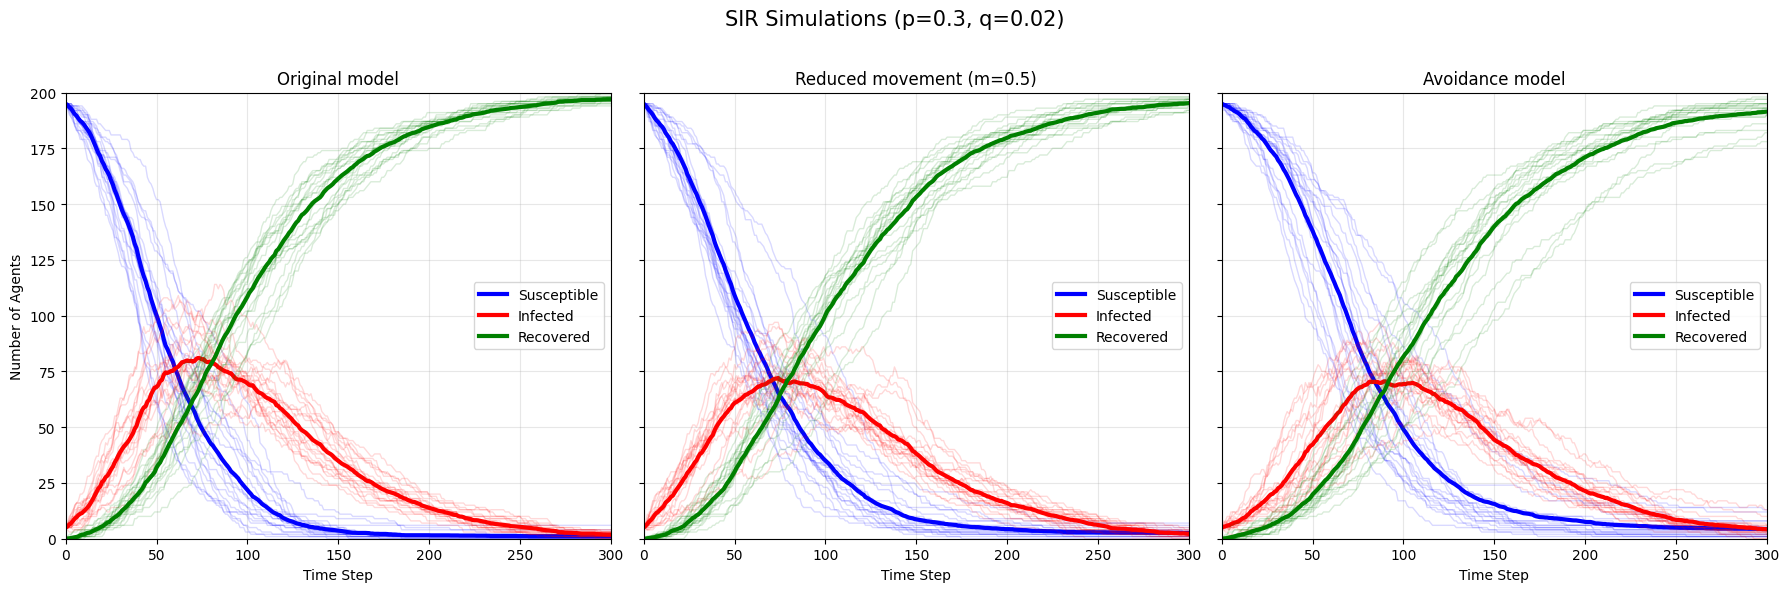

In [12]:
# Simulation settings
p, q = 0.3, 0.02
m = 0.5
grid_size, n_agents = 20, 200
n_steps, n_runs = 300, 20

measures = ['original', 'reduced', 'avoidance']
results_comparison = {}

# Run 20 simulations per model using the same seed list
for measure in measures:
    runs = []

    for seed in range(n_runs):
        if measure == 'original':
            counts = simulate(p, q, seed=seed)
        else:
            counts = simulate_distancing(
                p, q, measure, m=m, seed=seed
            )

        runs.append(counts)

    results_comparison[measure] = np.array(runs)

# Plot settings
state_names = ['Susceptible', 'Infected', 'Recovered']
colors = ['blue', 'red', 'green']
titles = [
    'Original model',
    f'Reduced movement (m={m})',
    'Avoidance model'
]
time = np.arange(n_steps + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)

for ax, measure, title in zip(axes, measures, titles):
    runs = results_comparison[measure]
    average = runs.mean(axis=0)

    for i, (name, color) in enumerate(zip(state_names, colors)):
        # Individual simulation trajectories
        for run in runs:
            ax.plot(
                time, run[:, i],
                color=color, alpha=0.15, linewidth=1
            )

        # Average across all 20 runs at each time step
        ax.plot(
            time, average[:, i],
            color=color, linewidth=3, label=name
        )

    ax.set_title(title)
    ax.set_xlabel('Time Step')
    ax.set_xlim(0, n_steps)
    ax.set_ylim(0, n_agents)
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel('Number of Agents')

fig.suptitle(f'SIR Simulations (p={p}, q={q})\n',fontsize=15)

fig.tight_layout()
fig.savefig(
    'sir_models_individual_runs_and_average.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

In [10]:
for measure, title in zip(measures, titles):
    infected = results_comparison[measure][:, :, 1]

    # Peak height and time for each individual run
    peak_heights = infected.max(axis=1)
    peak_times = infected.argmax(axis=1)

    # Peak of the average infection curve shown in the plot
    average_infected = infected.mean(axis=0)
    average_curve_peak_time = int(average_infected.argmax())
    average_curve_peak_height = average_infected[average_curve_peak_time]

    print(f'\n{title}')
    print(f'  Mean individual peak height: {peak_heights.mean():.2f} agents')
    print(f'  Mean individual time to peak: {peak_times.mean():.2f} steps')
    print(f'  Average curve peak height: {average_curve_peak_height:.2f} agents')
    print(f'  Average curve time to peak: {average_curve_peak_time} steps')


Original model
  Mean individual peak height: 89.10 agents
  Mean individual time to peak: 71.60 steps
  Average curve peak height: 81.05 agents
  Average curve time to peak: 73 steps

Reduced movement (m=0.5)
  Mean individual peak height: 78.95 agents
  Mean individual time to peak: 73.85 steps
  Average curve peak height: 72.05 agents
  Average curve time to peak: 74 steps

Avoidance model
  Mean individual peak height: 79.10 agents
  Mean individual time to peak: 92.75 steps
  Average curve peak height: 70.55 agents
  Average curve time to peak: 90 steps
